# Baum and Srivastava–Yeh equation sets

This notebook compares the `baum_etal` and default `srivastava_yeh` sets with identical physical inputs and numerical controls. It separates three questions: how a given conductivity becomes pressure and moisture, how those differences affect the reconstructed water table and stability, and how the two implementations approximate the first moments after an infiltration change.

The [equation-set comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets) explains the constitutive formulas; [water-table rise](/unsatstab/fundamentals/#water-table-rise) explains storage and pore filling. The sets combine the analytical unsaturated-flow response with the package's storage-based water-table reconstruction. Neither is a transient saturated-diffusion model.

These are controlled comparisons between package configurations, not digitized published benchmarks or field validation. The [Srivastava–Yeh Example 1 notebooks](/unsatstab/verification/04_srivastava_yeh_homogeneous_soils/) provide the independent numerical and published-figure comparisons.

In [1]:
%matplotlib inline
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import tol_colors as tc
from IPython.display import display
import unsatstab as us
from unsatstab.analytical import (
    initial_conductivity, pressure_from_conductivity,
    water_content_from_pressure, profile_at_time,
)
from unsatstab.roots import compute_roots

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
labels = {"srivastava_yeh": "Srivastava–Yeh", "baum_etal": "Baum et al."}
colors = {"srivastava_yeh": tc.colorsets["high_contrast"].blue,
          "baum_etal": tc.colorsets["high_contrast"].yellow}
styles = {"srivastava_yeh": "-", "baum_etal": "--"}


hydro = us.HydraulicProperties(
    slope_angle_deg=40.0, maximum_depth=1.0, initial_water_table_depth=1.0,
    saturated_hydraulic_conductivity=1.0e-5, alpha=3.0,
    theta_s=0.41, theta_r=0.06, long_term_infiltration=1.5e-7,
    n_roots=120, n_depths=120,
)
hydraulic_sets = {name: replace(hydro, equation_set=name) for name in labels}
strength = us.StrengthProperties(
    cohesion=3000.0, friction_angle_deg=33.6, unit_weight_soil=18000.0,
)
rainfall = us.RainfallSeries.constant(intensity=4.5, duration=24.0)
boundary = us.FinitePerchedBoundary(drainage_efficiency=0.1)
output_times = np.arange(0.0, rainfall.duration + 0.125, 0.25)  # hours
print(f"Package version: {us.__version__}")
display(pd.DataFrame({
    "Quantity": ["Slope", "Column / initial water-table depth", "Saturated conductivity",
                 "Gardner parameter", "Background infiltration", "Rainfall / duration", "Drainage efficiency"],
    "Value": [f"{hydro.slope_angle_deg:g} degrees", f"{hydro.maximum_depth:g} m",
              f"{hydro.saturated_hydraulic_conductivity * 3.6e6:g} mm/h",  # convert m/s to mm/h
              f"{hydro.alpha:g} 1/m",
              f"{hydro.long_term_infiltration * 3.6e6:g} mm/h",  # convert m/s to mm/h
              f"{rainfall.max_flux * 3.6e6:g} mm/h / {rainfall.duration:g} h",  # convert m/s to mm/h
              boundary.drainage_efficiency],
}))

Package version: 1.0.0


,Quantity,Value
0,Slope,40 degrees
1,Column / initial water-table depth,1 m
2,Saturated conductivity,36 mm/h
3,Gardner parameter,3 1/m
4,Background infiltration,0.54 mm/h
5,Rainfall / duration,4.5 mm/h / 24 h
6,Drainage efficiency,0.1


## Pressure and moisture at the same conductivity

Here $
ho=K/K_{mathrm{s}}$ is relative conductivity. Comparing both conversions at the same $
ho$ isolates their constitutive difference before water-table reconstruction. At a nonzero slope the Baum set gives stronger suction but greater water content for the same conductivity. Those two changes should not be interpreted as a single physical retention curve shared by both sets.

At zero slope, the pressure and moisture conversions coincide. The check below verifies that limiting case; it does not assert equality of the short-time numerical approximations.

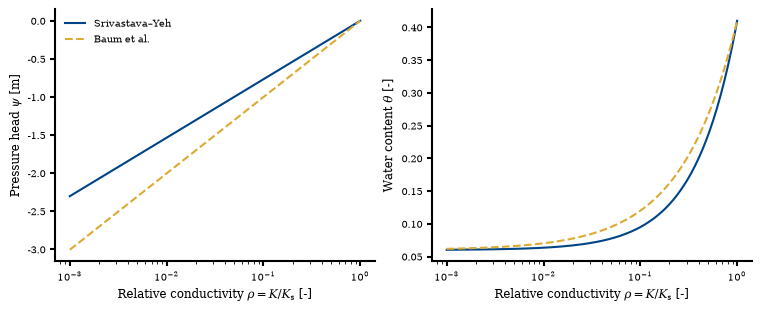

,Set,Relative conductivity,Pressure head [m],Water content [-]
0,Srivastava–Yeh,0.1,-0.7675,0.095
1,Baum et al.,0.1,-1.0019,0.120


In [2]:
rho = np.geomspace(1e-3, 1.0, 160)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0), constrained_layout=True)
rows = []
for name, h in hydraulic_sets.items():
    pressure = pressure_from_conductivity(rho * h.saturated_hydraulic_conductivity, hydro=h)
    moisture = water_content_from_pressure(pressure, hydro=h)
    axes[0].semilogx(rho, pressure, color=colors[name], ls=styles[name], lw=1.5, label=labels[name])
    axes[1].semilogx(rho, moisture, color=colors[name], ls=styles[name], lw=1.5)
    pressure_at_ratio = pressure_from_conductivity(np.array([0.1 * h.saturated_hydraulic_conductivity]), hydro=h)
    rows.append({"Set": labels[name], "Relative conductivity": 0.1,
                 "Pressure head [m]": pressure_at_ratio[0],
                 "Water content [-]": water_content_from_pressure(pressure_at_ratio, hydro=h)[0]})
axes[0].set_ylabel(r"Pressure head $\psi$ [m]")
axes[1].set_ylabel(r"Water content $\theta$ [-]")
for ax in axes:
    ax.set_xlabel(r"Relative conductivity $\rho=K/K_{\mathrm{s}}$ [-]")
axes[0].legend()
plt.show()
display(pd.DataFrame(rows).round(4))

horizontal = {name: replace(h, slope_angle_deg=0.0) for name, h in hydraulic_sets.items()}
p_horizontal = {name: pressure_from_conductivity(rho * h.saturated_hydraulic_conductivity, hydro=h)
                for name, h in horizontal.items()}
np.testing.assert_allclose(p_horizontal["baum_etal"], p_horizontal["srivastava_yeh"])
np.testing.assert_allclose(
    water_content_from_pressure(p_horizontal["baum_etal"], hydro=horizontal["baum_etal"]),
    water_content_from_pressure(p_horizontal["srivastava_yeh"], hydro=horizontal["srivastava_yeh"]),
)

The figure compares the implemented conversions described in the [parallel equation table](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets). The sources are [Baum et al. (2010)](https://doi.org/10.1029/2009JF001321) and the Gardner relations used by [Srivastava and Yeh (1991)](https://doi.org/10.1029/90WR02772). There is no published reference image for this combined comparison.

## Water-table rise and stability during the same storm

Both runs start with the water table at the 1 m column base and receive 108 mm over 24 hours. The selected observation plane is that same base. The full pressure, moisture and factor-of-safety profiles are nevertheless calculated throughout the column.

The imposed infiltration, roots and drainage capacity are identical. At the sampled times used here the basal transfer and retained storage also coincide. The two moisture conversions give different pore volumes available for filling, so equal stored water need not produce equal water-table rise. The reconstructed saturated-pressure gradients also differ when background infiltration is nonzero. These effects combine in the factor of safety; a greater rise alone does not determine which set produces the lower value.

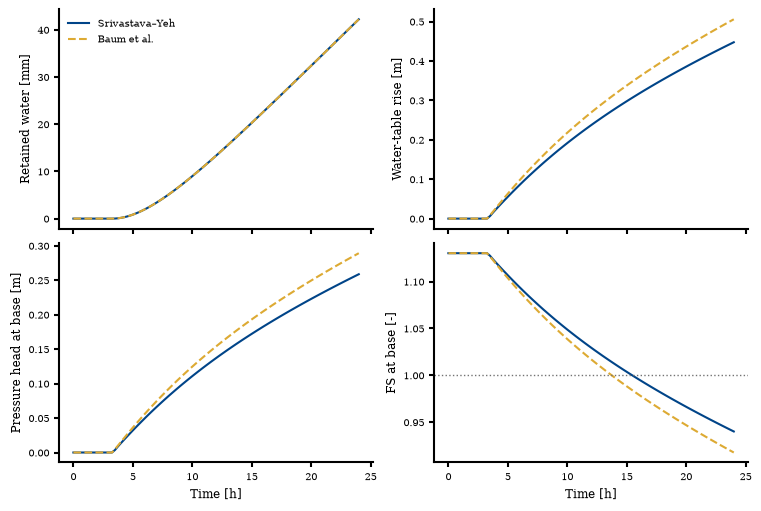

,Set,Maximum sampled rise [m],Minimum sampled base FS,First sampled base FS <= 1 [h],Minimum sampled full-column FS
0,Srivastava–Yeh,0.4475,0.9401,15.50,0.9401
1,Baum et al.,0.5057,0.9176,13.75,0.9176


In [3]:
results = {
    name: us.run_single_column(
        hydro=h, strength=strength, boundary=boundary, rainfall=rainfall,
        output_times=output_times, depth_to_failure_plane=hydro.maximum_depth,
        storage_time_step=5.0 / 60.0,  # convert minutes to hours
    ) for name, h in hydraulic_sets.items()
}
np.testing.assert_allclose(results["baum_etal"].basal_flux, results["srivastava_yeh"].basal_flux)
np.testing.assert_allclose(results["baum_etal"].cumulative_excess, results["srivastava_yeh"].cumulative_excess)
fig, axes = plt.subplots(2, 2, figsize=(7.5, 5.0), sharex=True, constrained_layout=True)
fields = ["cumulative_excess", "water_table_rise", "pressure_head_at_failure_plane", "factor_of_safety_at_failure_plane"]
ylabels = ["Retained water [mm]", "Water-table rise [m]", "Pressure head at base [m]", "FS at base [-]"]
for ax, field, ylabel in zip(axes.flat, fields, ylabels):
    for name, result in results.items():
        values = getattr(result, field)
        if field == "cumulative_excess":
            values = values * 1000.0  # convert metres of water to millimetres
        ax.plot(result.time, values, color=colors[name], ls=styles[name], lw=1.5, label=labels[name])
    ax.set_ylabel(ylabel)
axes[1, 1].axhline(1.0, color="0.45", ls=":", lw=1.0)
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
plt.show()
rows = []
for name, result in results.items():
    crossings = result.time[result.factor_of_safety_at_failure_plane <= 1.0]
    rows.append({"Set": labels[name], "Maximum sampled rise [m]": result.water_table_rise.max(),
                 "Minimum sampled base FS": result.factor_of_safety_at_failure_plane.min(),
                 "First sampled base FS <= 1 [h]": crossings[0] if len(crossings) else np.nan,
                 "Minimum sampled full-column FS": result.arrays()["factor_of_safety"].min()})
display(pd.DataFrame(rows).round(4))

## Pressure, moisture and stability over depth

The profiles show where the differences occur, rather than only reporting the column base. Depth increases downward. Dashed horizontal guides mark each set's reconstructed water table. Above it the analytical unsaturated profiles are retained; below it the package applies its saturated reconstruction. Abrupt joins reflect that approximation and are not a resolved moving wetting front.

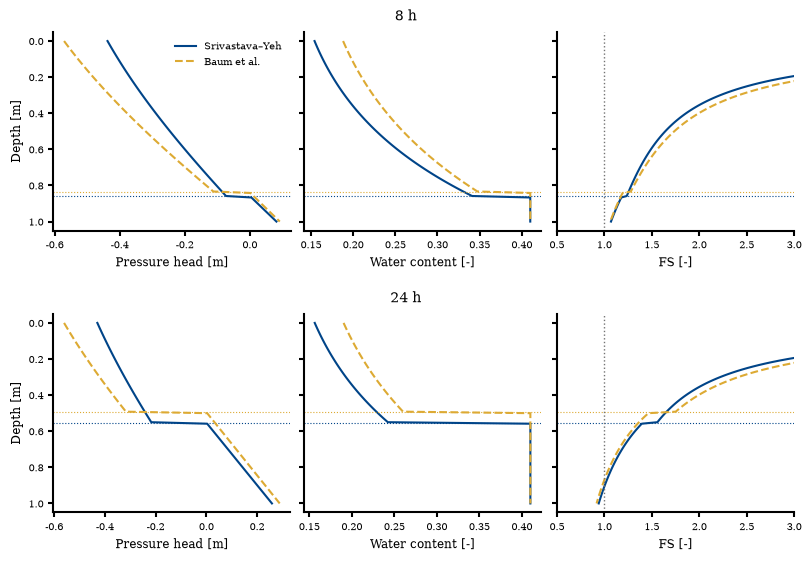

In [4]:
fig = plt.figure(figsize=(8.0, 5.5), constrained_layout=True)
row_figures = fig.subfigures(2, 1, hspace=0.05)
axes = np.empty((2, 3), dtype=object)

for row, (time, row_figure) in enumerate(zip([8.0, 24.0], row_figures)):
    axes[row] = row_figure.subplots(1, 3, sharey=True)
    row_figure.suptitle(f"{time:g} h", fontsize=10)
    if row > 0:
        axes[row, 0].sharey(axes[0, 0])
    index = np.flatnonzero(np.isclose(output_times, time))[0]
    for col, (field, xlabel) in enumerate([
        ("pressure_head_total", "Pressure head [m]"), ("theta", "Water content [-]"),
        ("factor_of_safety", "FS [-]"),
    ]):
        ax = axes[row, col]
        for name, result in results.items():
            arrays = result.arrays()
            ax.plot(arrays[field][index], arrays["z"], color=colors[name], ls=styles[name], lw=1.5, label=labels[name])
            ax.axhline(result.water_table_depth[index], color=colors[name], ls=":", lw=0.8)
        ax.set_xlabel(xlabel)
        if col == 0:
            ax.set_ylabel("Depth [m]")
        if field == "factor_of_safety":
            ax.set_xlim(0.5, 3.0)  # focus on the stability range; full arrays remain available
            ax.axvline(1.0, color="0.45", ls=":", lw=1.0)
axes[0, 0].invert_yaxis()
axes[0, 0].legend()
plt.show()

## Separating the very early-time approximation

The preceding storm plots use output intervals of 15 minutes. The following plot instead examines the first moments after the surface infiltration changes, without replacing any part of the fixed-domain profile with the moving saturated region.

Elapsed time is expressed as $t^*=aK_{\mathrm{s}}\tau/(\theta_{\mathrm{s}}-\theta_{\mathrm{r}})$, with $a=\alpha\cos^2\delta$ and $\tau$ in seconds. The plotted quantity is the surface-conductivity increase divided by the imposed flux increase $\Delta I$. The consistent linear-flow solution approaches $2\sqrt{t^*/\pi}$ as $t^*\to0$. The Baum et al. profile approximation uses a different leading coefficient. This is a numerical approximation difference, separate from converting conductivity to pressure and moisture.

See [early-time response](/unsatstab/fundamentals/#evaluating-the-response-at-short-times) for the scope of the comparison.

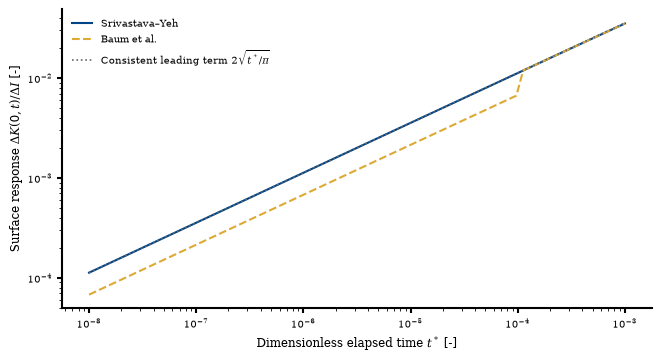

In [5]:
t_star = np.geomspace(1e-8, 1e-3, 80)
elapsed_hours = t_star / hydro.time_factor  # time_factor is in 1/h; resulting time is hours
flux_increment = rainfall.fluxes[0] - hydro.long_term_infiltration
initial_surface_k = initial_conductivity(np.array([0.0]), hydro=hydro)[0]
fig, ax = plt.subplots(figsize=(6.5, 3.5), constrained_layout=True)
for name, h in hydraulic_sets.items():
    roots = compute_roots(h.transformed_alpha, h.initial_water_table_depth, h.n_roots)
    response = np.array([
        (profile_at_time(time, h, rainfall, roots=roots, evaluation_depths=np.array([0.0]))
         ["hydraulic_conductivity"][0] - initial_surface_k) / flux_increment
        for time in elapsed_hours
    ])
    ax.loglog(t_star, response, color=colors[name], ls=styles[name], lw=1.5, label=labels[name])
ax.loglog(t_star, 2.0 * np.sqrt(t_star / np.pi), color="0.4", ls=":", lw=1.2,
          label=r"Consistent leading term $2\sqrt{t^*/\pi}$")
ax.set_xlabel(r"Dimensionless elapsed time $t^*$ [-]")
ax.set_ylabel(r"Surface response $\Delta K(0,t)/\Delta I$ [-]")
ax.legend()
plt.show()

The default set resolves additional analytical terms or uses the short-time half-space response when appropriate. The Baum set uses the TRIGRS profile approximation. This plot compares their surface responses under the specified forcing. The [verification scope](/unsatstab/verification/) distinguishes this check from the separate Fortran basal-flux regression.

For this experiment, conductivity-to-moisture conversion changes water-table rise even though retained storage is the same. Pressure conversion and the saturated gradient also affect stability. The summary table reports sampled thresholds, not exact crossing times. These observations apply to the specified inputs; the combined effect on FS should be assessed for each application.